# Exploratory Sentiment Analysis

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load existing sentiment predictions
input_dir = Path("../data/processed")

# Output directories
figures_dir = Path("../results/figures/sentiment")
tables_dir = Path("../results/tables/sentiment")

figures_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

companies = ["adidas", "puma", "asics", "mizuno"]

# Model labels and colors
model_names = {
    "financial_roberta": "Financial-RoBERTa",
    "finbert": "FinBERT"
}

model_colors = {
    "financial_roberta": "#527DA5",
    "finbert": "#D88A48"
}

# Load each company's sentiment predictions separately
results = {}

for company in companies:

    path = input_dir / f"{company}_sentiment.xlsx"

    if not path.exists():
        raise FileNotFoundError(
            f"Missing {path}. Run 02_sentiment.ipynb first."
        )

    df = pd.read_excel(
        path,
        sheet_name=0,
        dtype={"ID": "string"}
    )

    required = [
        "ID", "Year", "Leadership_context",
        "Information_valence"
    ]

    for model_key in model_names:
        required += [
            f"{model_key}_positive_prob",
            f"{model_key}_negative_prob",
            f"{model_key}_sentiment"
        ]

    missing = [
        column for column in required
        if column not in df.columns
    ]

    if missing:
        raise ValueError(
            f"Missing columns in {path.name}: {missing}"
        )

    # Calculate continuous sentiment scores
    for model_key in model_names:

        df[f"{model_key}_score"] = (
            pd.to_numeric(
                df[f"{model_key}_positive_prob"],
                errors="coerce"
            )
            -
            pd.to_numeric(
                df[f"{model_key}_negative_prob"],
                errors="coerce"
            )
        )

    results[company] = df

    print(f"{company.capitalize()}: {len(df)} observations loaded")


def save_sentiment_figure(fig, company, name):
    """Save figures in PDF format."""

    fig.savefig(
        figures_dir / f"{company}_{name}.pdf",
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

Adidas: 219 observations loaded
Puma: 105 observations loaded
Asics: 206 observations loaded
Mizuno: 62 observations loaded


## 1. Distribution of Sentiment Scores

This analysis examines the distribution of continuous linguistic sentiment scores estimated by Financial-RoBERTa and FinBERT.

Sentiment scores range from −1 to +1, with negative values indicating negative linguistic sentiment and positive values indicating positive linguistic sentiment.

The distributions are examined separately for each company and model. Descriptive statistics are calculated to summarize the central tendency and dispersion of sentiment scores.

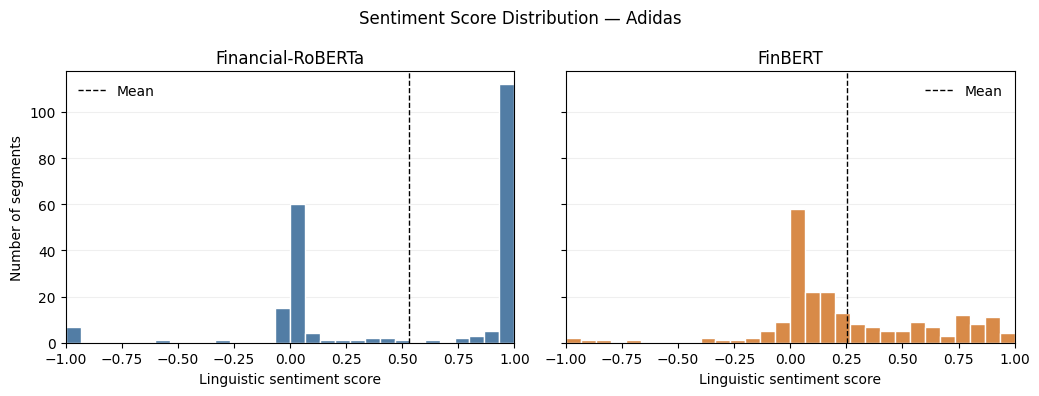


Sentiment Score Summary — Adidas


,model,n,mean,median,std,q25,q75
0,Financial-RoBERTa,219,0.530,0.961,0.547,0.001,0.997
1,FinBERT,219,0.252,0.147,0.361,0.029,0.525


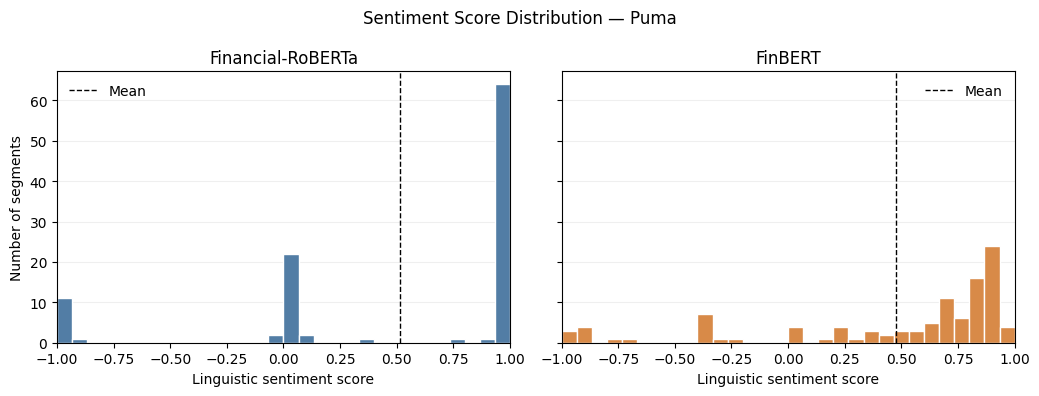


Sentiment Score Summary — Puma


,model,n,mean,median,std,q25,q75
0,Financial-RoBERTa,105,0.517,0.996,0.685,0.001,0.998
1,FinBERT,105,0.476,0.725,0.558,0.247,0.872


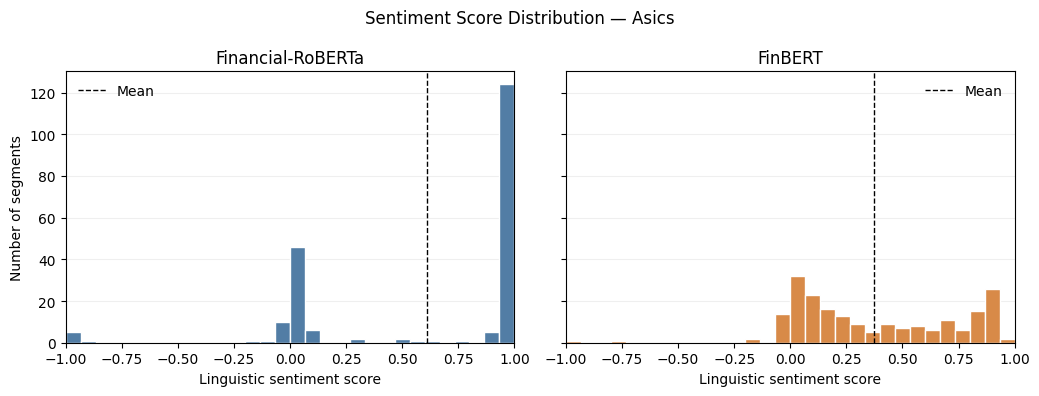


Sentiment Score Summary — Asics


,model,n,mean,median,std,q25,q75
0,Financial-RoBERTa,206,0.612,0.996,0.530,0.006,0.997
1,FinBERT,206,0.373,0.270,0.358,0.072,0.714


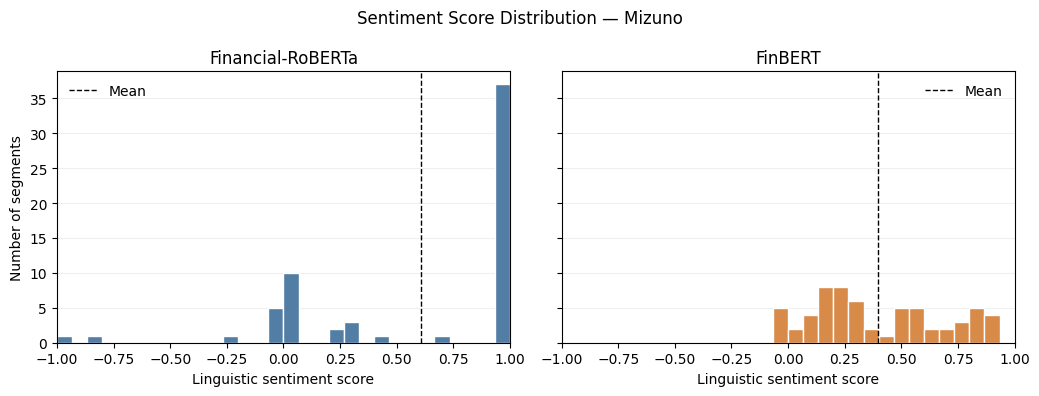


Sentiment Score Summary — Mizuno


,model,n,mean,median,std,q25,q75
0,Financial-RoBERTa,62,0.605,0.995,0.526,0.009,0.997
1,FinBERT,62,0.395,0.307,0.282,0.179,0.604


In [15]:
bins = np.linspace(-1, 1, 31)

for company, df in results.items():

    rows = []

    fig, axes = plt.subplots(
        1, 2,
        figsize=(10.5, 4),
        sharex=True,
        sharey=True
    )

    for ax, (model_key, model_label) in zip(
        axes, model_names.items()
    ):

        scores = df[f"{model_key}_score"].dropna()

        # Descriptive statistics
        rows.append({
            "model": model_label,
            "n": len(scores),
            "mean": scores.mean(),
            "median": scores.median(),
            "std": scores.std(),
            "q25": scores.quantile(0.25),
            "q75": scores.quantile(0.75)
        })

        # Histogram
        ax.hist(
            scores,
            bins=bins,
            color=model_colors[model_key],
            edgecolor="white"
        )

        # Mean sentiment score
        if len(scores):
            ax.axvline(
                scores.mean(),
                color="black",
                linestyle="--",
                linewidth=1,
                label="Mean"
            )

            ax.legend(frameon=False)

        ax.set_title(model_label)
        ax.set_xlabel("Linguistic sentiment score")
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)

    axes[0].set_ylabel("Number of segments")
    axes[0].set_xlim(-1, 1)

    fig.suptitle(
        f"Sentiment Score Distribution — {company.capitalize()}"
    )

    fig.tight_layout()

    # Save PDF figure
    save_sentiment_figure(
        fig, company, "score_distribution"
    )

    # Descriptive statistics table
    summary_df = pd.DataFrame(rows).round(3)

    # Display table in Jupyter
    print(f"\nSentiment Score Summary — {company.capitalize()}")
    display(summary_df)

    # Save table as CSV
    summary_df.to_csv(
        tables_dir / f"{company}_score_summary.csv",
        index=False
    )

For Puma, Financial-RoBERTa and FinBERT show a Pearson correlation of 0.637 and an exact classification agreement of 76.19%. Although the models demonstrate a degree of consistency, differences remain in their sentiment predictions. These findings suggest that sentiment measurement is sensitive to model selection and support the use of both models to assess the robustness of the empirical results.

## 2. Sentiment by Leadership Context and Information Valence

This analysis examines how linguistic sentiment varies across the manually classified Leadership Contexts and Information Valence categories.

The median sentiment score and interquartile range are used to describe the distribution of sentiment within each category.

Information Valence represents the favorability of the underlying information, whereas linguistic sentiment captures the evaluative orientation expressed through language.

The analysis provides descriptive evidence relevant to the subsequent regression models, without controlling for other explanatory variables.

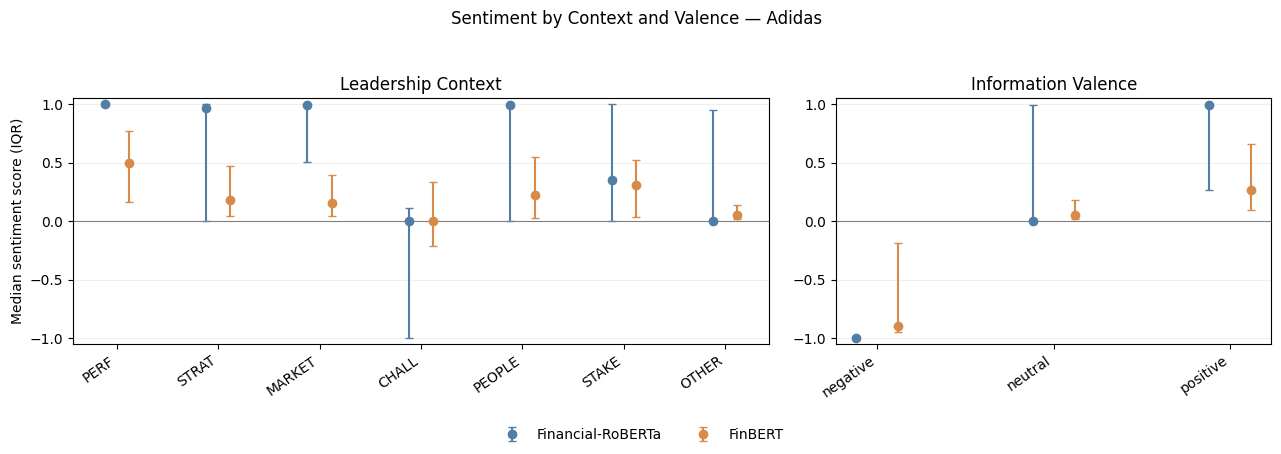

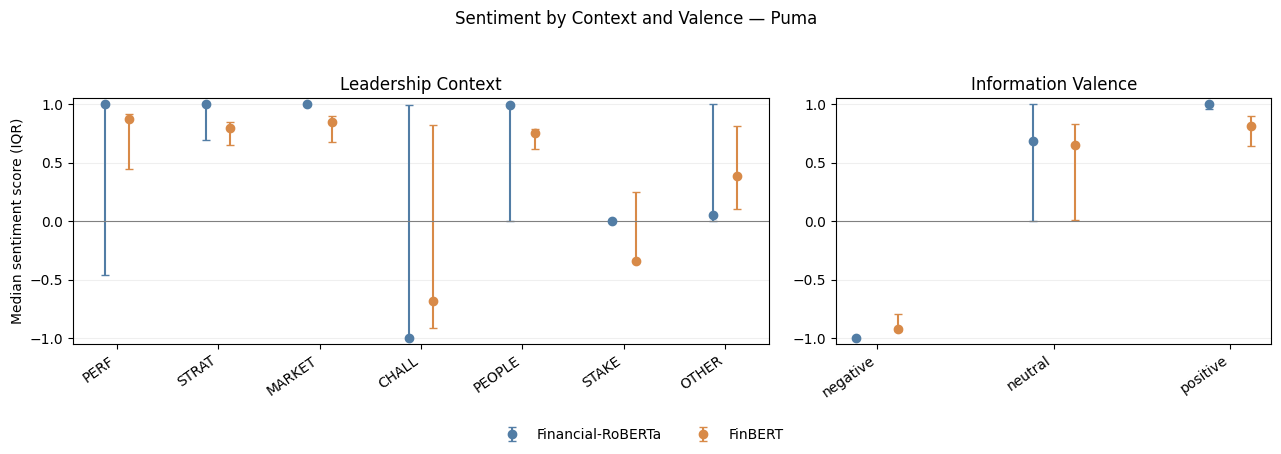

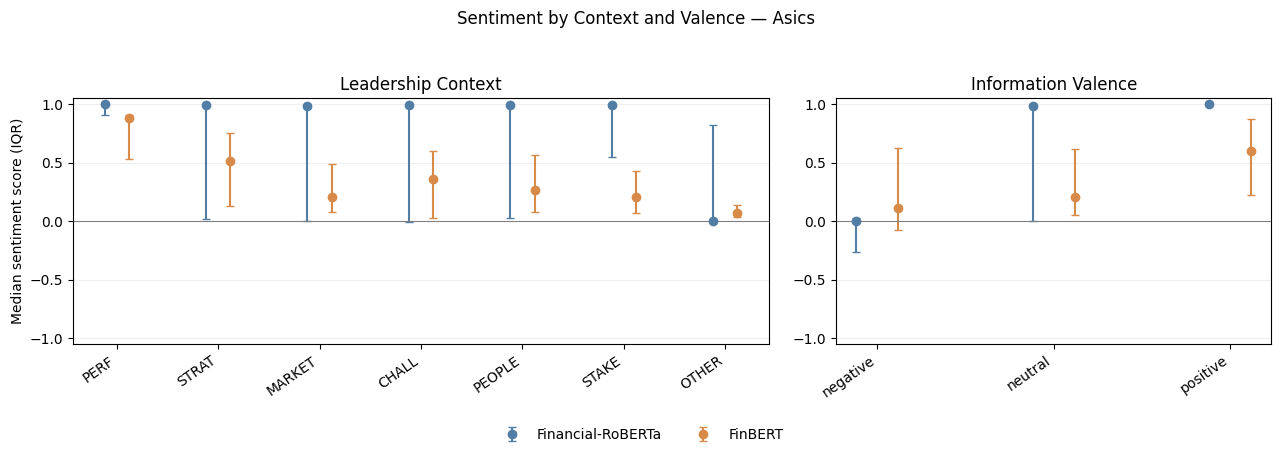

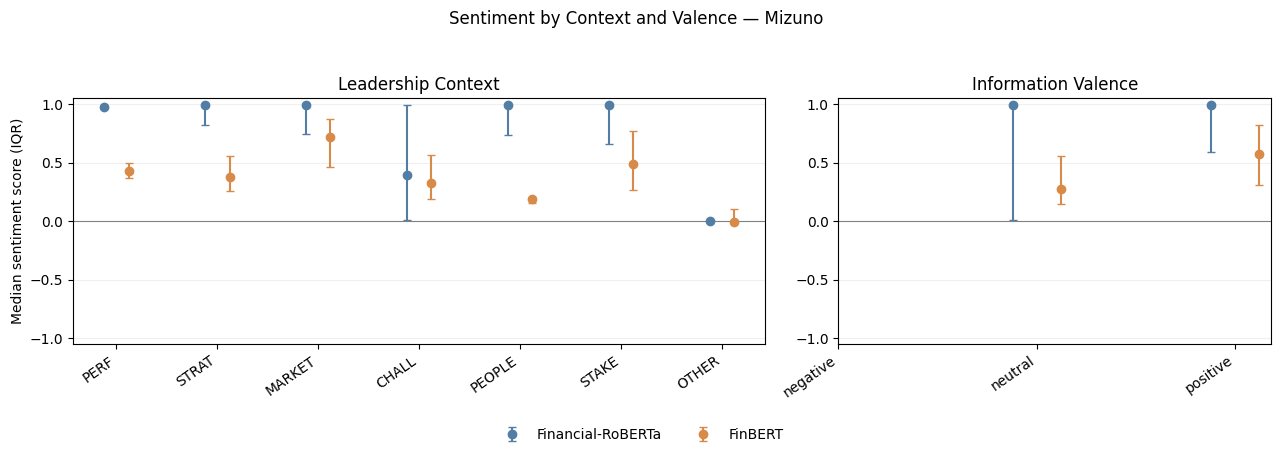

In [11]:
context_order = [
    "PERF", "STRAT", "MARKET",
    "CHALL", "PEOPLE", "STAKE", "OTHER"
]

valence_order = ["negative", "neutral", "positive"]


def group_summary(df, group_column, order):

    labels = df[group_column].astype("string").str.strip()

    if group_column == "Leadership_context":
        labels = labels.str.upper()
    else:
        labels = labels.str.lower()

    rows = []

    for group in order:

        mask = labels.eq(group).fillna(False)

        for model_key, model_label in model_names.items():

            scores = df.loc[
                mask, f"{model_key}_score"
            ].dropna()

            rows.append({
                "category": group,
                "model": model_label,
                "n": len(scores),
                "mean": scores.mean(),
                "median": scores.median(),
                "q25": scores.quantile(0.25),
                "q75": scores.quantile(0.75)
            })

    return pd.DataFrame(rows)


for company, df in results.items():

    # Calculate category summaries
    context_summary = group_summary(
        df, "Leadership_context", context_order
    )

    valence_summary = group_summary(
        df, "Information_valence", valence_order
    )

    # Save tables
    context_summary.round(3).to_csv(
        tables_dir / f"{company}_sentiment_by_context.csv",
        index=False
    )

    valence_summary.round(3).to_csv(
        tables_dir / f"{company}_sentiment_by_valence.csv",
        index=False
    )

    # Figure
    fig, axes = plt.subplots(
        1, 2,
        figsize=(13, 4.5),
        gridspec_kw={"width_ratios": [1.6, 1]}
    )

    panels = [
        (
            axes[0], context_summary,
            context_order, "Leadership Context"
        ),
        (
            axes[1], valence_summary,
            valence_order, "Information Valence"
        )
    ]

    for ax, summary, order, title in panels:

        positions = np.arange(len(order))

        for i, (model_key, model_label) in enumerate(
            model_names.items()
        ):

            tab = (
                summary.loc[summary["model"].eq(model_label)]
                .set_index("category")
                .reindex(order)
            )

            median = tab["median"]
            q25 = tab["q25"]
            q75 = tab["q75"]

            valid = median.notna()

            x = positions[valid] + (
                -0.12 if i == 0 else 0.12
            )

            # Interquartile range
            yerr = np.vstack([
                (median[valid] - q25[valid]).to_numpy(),
                (q75[valid] - median[valid]).to_numpy()
            ])

            ax.errorbar(
                x,
                median[valid],
                yerr=yerr,
                fmt="o",
                color=model_colors[model_key],
                capsize=3,
                label=model_label
            )

        ax.set_xticks(
            positions, order,
            rotation=35, ha="right"
        )

        ax.set_title(title)
        ax.set_ylim(-1.05, 1.05)
        ax.axhline(0, color="gray", linewidth=0.8)
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)

    axes[0].set_ylabel("Median sentiment score (IQR)")

    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        loc="lower center",
        ncol=2,
        frameon=False
    )

    fig.suptitle(
        f"Sentiment by Context and Valence — {company.capitalize()}"
    )

    fig.tight_layout(rect=(0, 0.08, 1, 0.94))

    save_sentiment_figure(
        fig, company, "context_valence_scores"
    )

## 3. Temporal Distribution of Sentiment

This analysis examines descriptive changes in average linguistic sentiment across the reporting period from 2020 to 2025.

Annual mean sentiment scores are calculated separately for each company and sentiment model.

The analysis identifies potential temporal patterns in corporate leadership communication without attributing observed changes to specific organisational or external events.

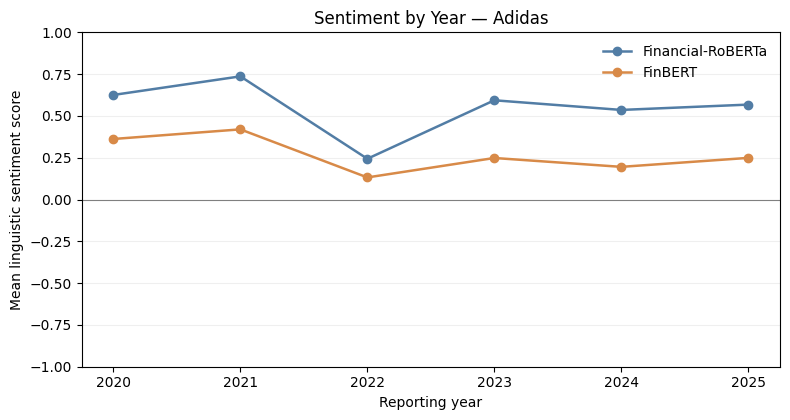

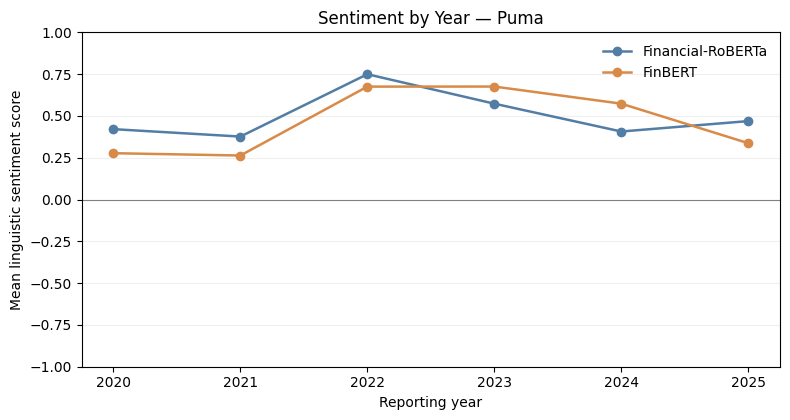

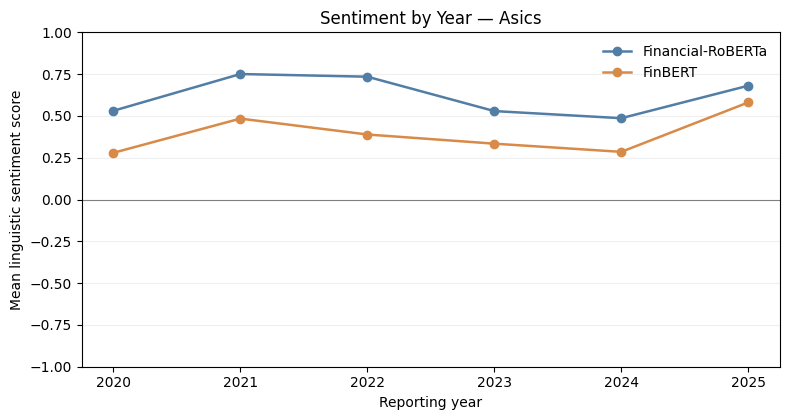

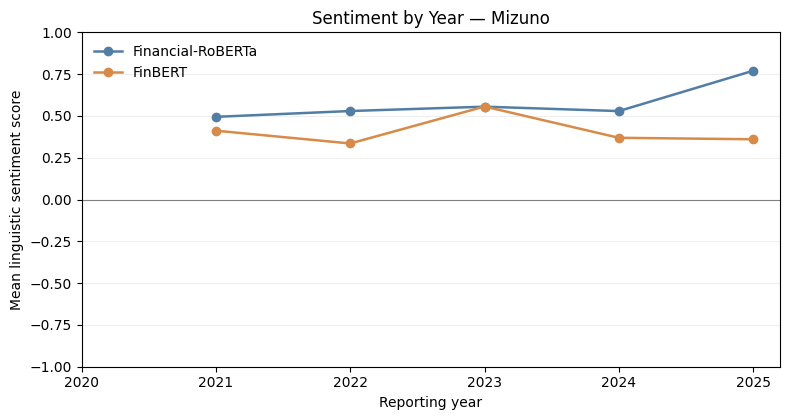

In [7]:
years = list(range(2020, 2026))

for company, df in results.items():

    rows = []

    fig, ax = plt.subplots(figsize=(8, 4.3))

    year_numeric = pd.to_numeric(
        df["Year"], errors="coerce"
    )

    for model_key, model_label in model_names.items():

        summary = (
            pd.DataFrame({
                "year": year_numeric,
                "score": df[f"{model_key}_score"]
            })
            .groupby("year")["score"]
            .agg(
                n="count",
                mean="mean",
                median="median"
            )
            .reindex(years)
        )

        # Annual mean sentiment
        ax.plot(
            years,
            summary["mean"],
            marker="o",
            linewidth=1.8,
            color=model_colors[model_key],
            label=model_label
        )

        for year, row in summary.iterrows():

            rows.append({
                "year": year,
                "model": model_label,
                "n": int(row["n"]) if pd.notna(row["n"]) else 0,
                "mean": row["mean"],
                "median": row["median"]
            })

    ax.set_xticks(years)
    ax.set_ylim(-1, 1)

    ax.set_ylabel("Mean linguistic sentiment score")
    ax.set_xlabel("Reporting year")

    ax.set_title(
        f"Sentiment by Year — {company.capitalize()}"
    )

    ax.axhline(
        0,
        color="gray",
        linewidth=0.8
    )

    ax.grid(axis="y", alpha=0.2)
    ax.legend(frameon=False)

    fig.tight_layout()

    save_sentiment_figure(
        fig, company, "sentiment_by_year"
    )

    # Save annual descriptive statistics
    pd.DataFrame(rows).round(3).to_csv(
        tables_dir / f"{company}_sentiment_by_year.csv",
        index=False
    )

## 4. Comparison Between Financial-RoBERTa and FinBERT

This analysis examines the consistency of sentiment estimates generated by Financial-RoBERTa and FinBERT.

Pearson and Spearman correlations are calculated to assess the association between continuous sentiment scores. Exact classification agreement measures the proportion of segments receiving the same linguistic sentiment category from both models.

Observations with different sentiment classifications are identified for further inspection.

Agreement between the two models indicates consistency of measurement but does not independently establish the validity of the sentiment classifications.

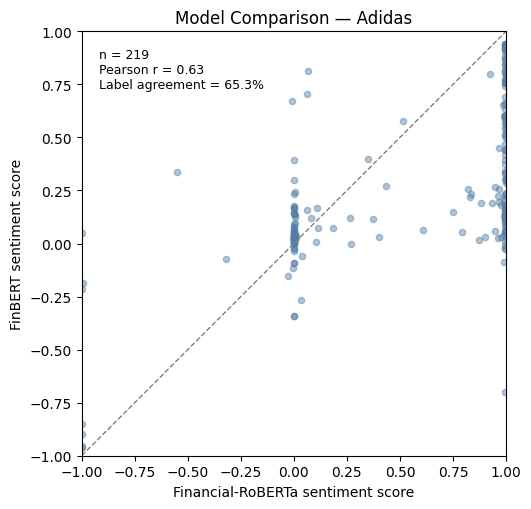

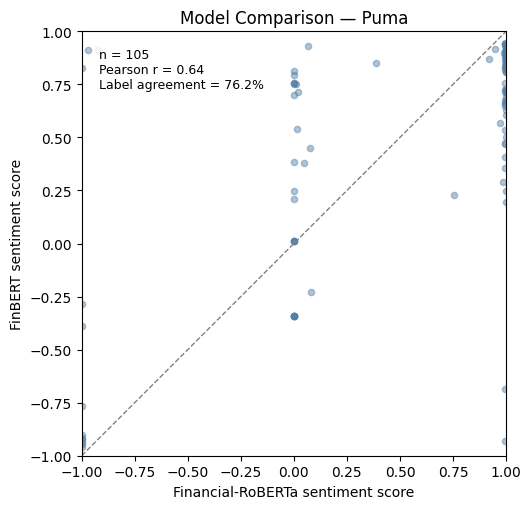

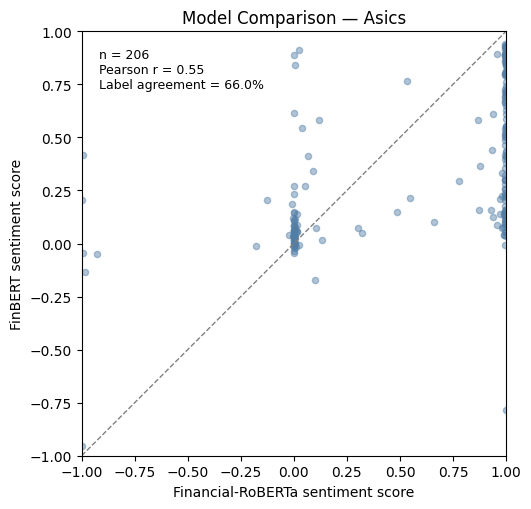

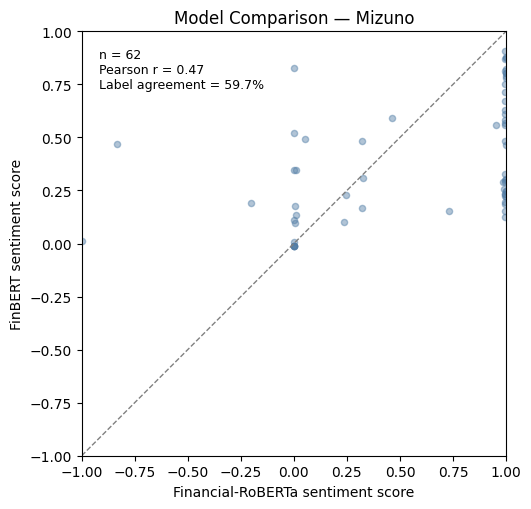

In [8]:
sentiment_order = ["negative", "neutral", "positive"]

for company, df in results.items():

    score_cols = [
        "financial_roberta_score",
        "finbert_score"
    ]

    label_cols = [
        "financial_roberta_sentiment",
        "finbert_sentiment"
    ]

    # Continuous sentiment scores
    paired = df[score_cols].dropna()

    # Normalize categorical predictions
    labels = df[label_cols].copy()

    for column in label_cols:
        labels[column] = (
            labels[column]
            .astype("string")
            .str.strip()
            .str.lower()
        )

    valid_labels = labels.notna().all(axis=1)

    # Correlations
    pearson = paired.iloc[:, 0].corr(
        paired.iloc[:, 1]
    )

    spearman = paired.iloc[:, 0].corr(
        paired.iloc[:, 1],
        method="spearman"
    )

    # Exact classification agreement
    exact_agreement = (
        100 * labels.loc[valid_labels, label_cols[0]]
        .eq(labels.loc[valid_labels, label_cols[1]])
        .mean()
        if valid_labels.any() else np.nan
    )

    # Save agreement summary
    summary = pd.DataFrame([{
        "n_score_pairs": len(paired),
        "pearson_r": pearson,
        "spearman_rho": spearman,
        "n_label_pairs": int(valid_labels.sum()),
        "exact_label_agreement_pct": exact_agreement
    }])

    summary.round(3).to_csv(
        tables_dir / f"{company}_model_agreement.csv",
        index=False
    )

    # Classification agreement matrix
    matrix = pd.crosstab(
        labels[label_cols[0]],
        labels[label_cols[1]]
    ).reindex(
        index=sentiment_order,
        columns=sentiment_order,
        fill_value=0
    )

    matrix.to_csv(
        tables_dir / f"{company}_model_agreement_matrix.csv"
    )

    # Export model disagreements
    disagreement = (
        valid_labels
        & labels[label_cols[0]].ne(labels[label_cols[1]])
    )

    columns = [
        "ID",
        "Leadership_context",
        "Information_valence",
        *label_cols,
        *score_cols
    ]

    df.loc[
        disagreement.fillna(False),
        columns
    ].to_csv(
        tables_dir / f"{company}_model_disagreements.csv",
        index=False
    )

    # Visualization
    fig, ax = plt.subplots(figsize=(5.7, 5.2))

    ax.scatter(
        paired[score_cols[0]],
        paired[score_cols[1]],
        color=model_colors["financial_roberta"],
        s=20,
        alpha=0.45
    )

    # Perfect agreement line
    ax.plot(
        [-1, 1],
        [-1, 1],
        color="gray",
        linestyle="--",
        linewidth=1
    )

    ax.set_xlim(-1, 1)
    ax.set_ylim(-1, 1)
    ax.set_aspect("equal", adjustable="box")

    ax.set_xlabel("Financial-RoBERTa sentiment score")
    ax.set_ylabel("FinBERT sentiment score")

    ax.set_title(
        f"Model Comparison — {company.capitalize()}"
    )

    ax.text(
        0.04,
        0.96,
        f"n = {len(paired)}\n"
        f"Pearson r = {pearson:.2f}\n"
        f"Label agreement = {exact_agreement:.1f}%",
        transform=ax.transAxes,
        va="top",
        fontsize=9,
        bbox={
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.85
        }
    )

    fig.tight_layout()

    save_sentiment_figure(
        fig,
        company,
        "model_comparison"
    )

### 3.5 Linguistic Sentiment vs. Information Valence

This analysis examines the relationship between manually coded Information Valence and the linguistic sentiment classifications predicted by Financial-RoBERTa and FinBERT.

For each Information Valence category, the analysis presents the proportion of segments classified as having negative, neutral, or positive linguistic sentiment.

The comparison highlights potential differences between the favorability of the underlying information and the linguistic tone used to communicate it.

Such differences are not necessarily classification errors or evidence of impression management, as Information Valence and Linguistic Sentiment represent distinct constructs.

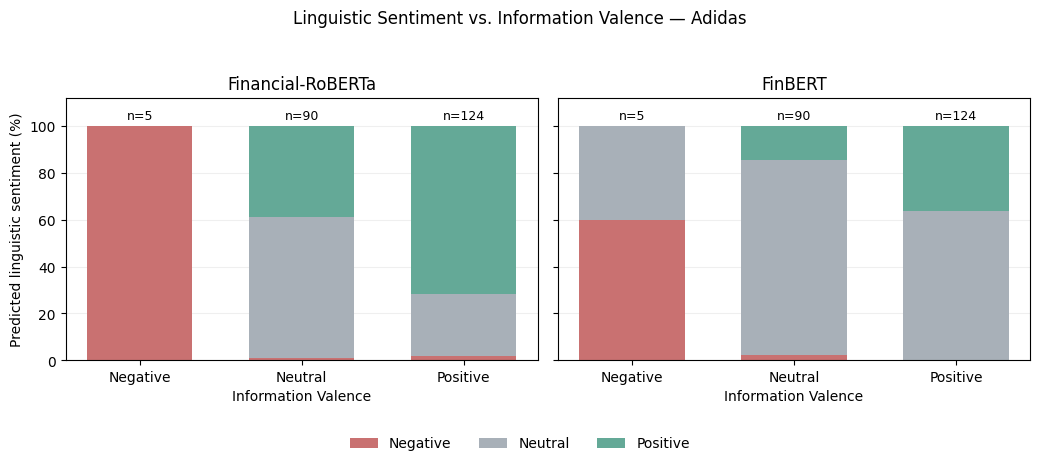

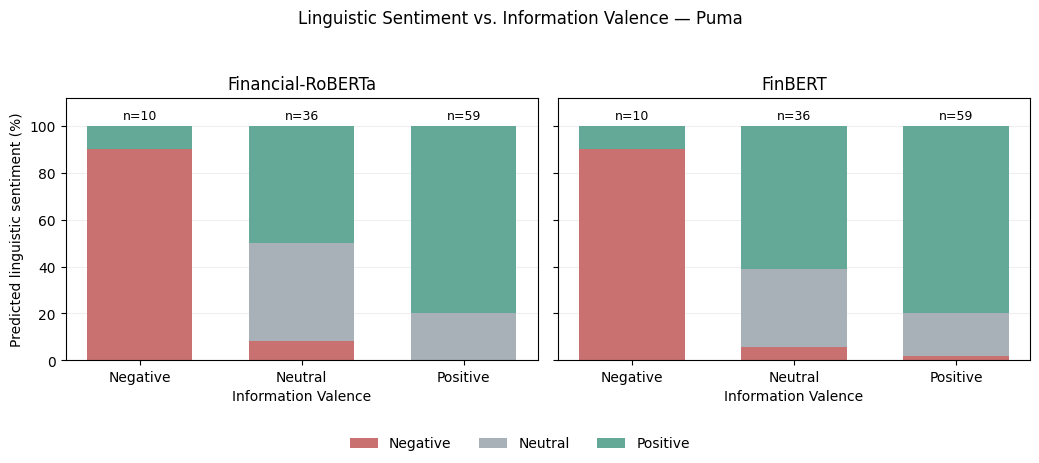

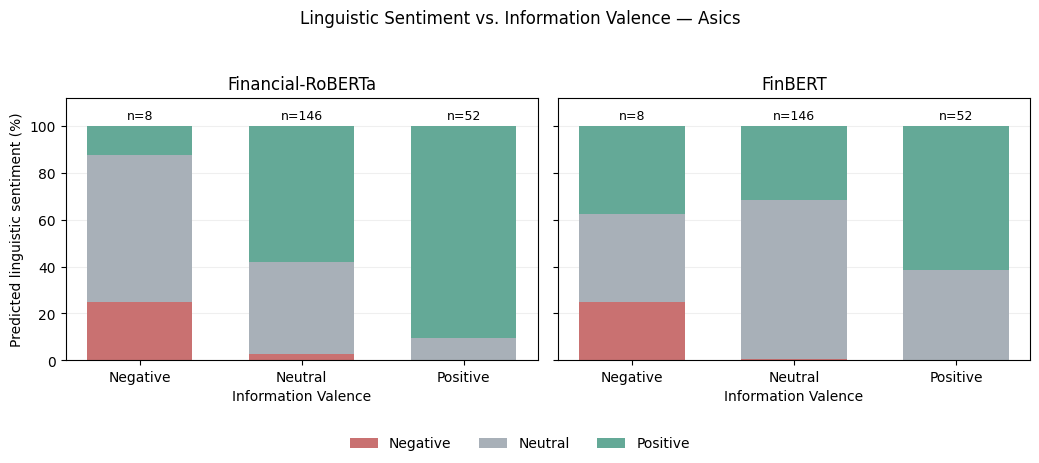

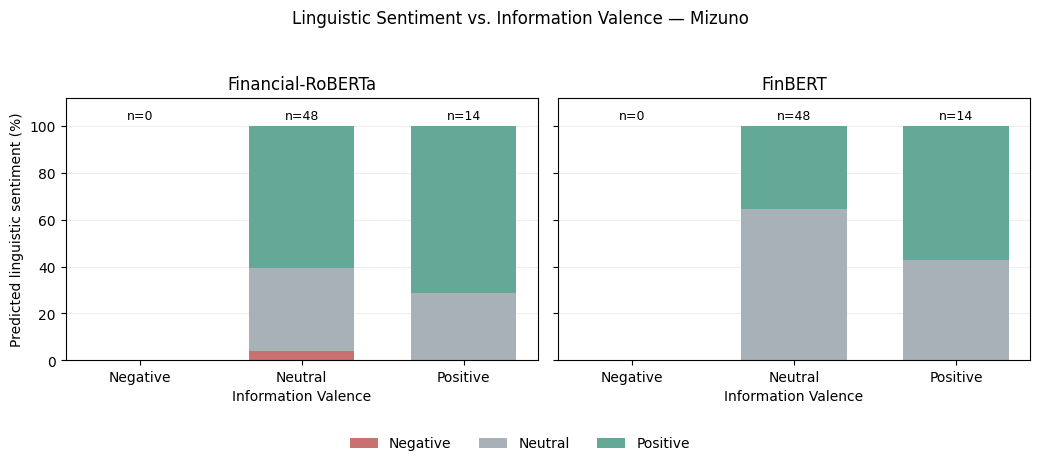

In [9]:
valence_order = ["negative", "neutral", "positive"]
sentiment_order = ["negative", "neutral", "positive"]

sentiment_colors = {
    "negative": "#C97171",
    "neutral": "#A8B0B8",
    "positive": "#64A997"
}

for company, df in results.items():

    valence = (
        df["Information_valence"]
        .astype("string")
        .str.strip()
        .str.lower()
    )

    fig, axes = plt.subplots(
        1, 2,
        figsize=(10.5, 4.6),
        sharey=True
    )

    for ax, (model_key, model_label) in zip(
        axes,
        model_names.items()
    ):

        sentiment = (
            df[f"{model_key}_sentiment"]
            .astype("string")
            .str.strip()
            .str.lower()
        )

        # Cross-tabulation
        counts = pd.crosstab(
            valence,
            sentiment
        ).reindex(
            index=valence_order,
            columns=sentiment_order,
            fill_value=0
        )

        n_by_valence = counts.sum(axis=1)

        # Within-valence percentages
        percentages = (
            counts.div(
                n_by_valence.replace(0, np.nan),
                axis=0
            ) * 100
        )

        # Save tables
        counts.to_csv(
            tables_dir /
            f"{company}_{model_key}_valence_sentiment_counts.csv"
        )

        percentages.round(2).to_csv(
            tables_dir /
            f"{company}_{model_key}_valence_sentiment_percentages.csv"
        )

        # Stacked bar chart
        bottom = np.zeros(len(valence_order))

        for category in sentiment_order:

            values = (
                percentages[category]
                .fillna(0)
                .to_numpy()
            )

            ax.bar(
                [label.capitalize() for label in valence_order],
                values,
                bottom=bottom,
                width=0.65,
                color=sentiment_colors[category],
                label=category.capitalize()
            )

            bottom += values

        # Sample size
        for i, n in enumerate(n_by_valence):

            ax.text(
                i,
                103,
                f"n={n}",
                ha="center",
                fontsize=9
            )

        ax.set_ylim(0, 112)
        ax.set_title(model_label)
        ax.set_xlabel("Information Valence")
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)

    axes[0].set_ylabel(
        "Predicted linguistic sentiment (%)"
    )

    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        loc="lower center",
        ncol=3,
        frameon=False
    )

    fig.suptitle(
        f"Linguistic Sentiment vs. Information Valence — "
        f"{company.capitalize()}"
    )

    fig.tight_layout(rect=(0, 0.09, 1, 0.94))

    save_sentiment_figure(
        fig,
        company,
        "valence_sentiment_comparison"
    )

Financial-RoBERTa produces considerably higher sentiment scores than FinBERT across Adidas, Asics, and Mizuno. In particular, Financial-RoBERTa's median scores approach +1, indicating a strong concentration of positive sentiment predictions. This difference highlights the importance of examining both models separately when interpreting the subsequent regression results.